In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sqlalchemy import text

%matplotlib inline

In [4]:
url = r"C:\Users\admin\Documents\Ironhack\Week05\amz_uk_price_prediction_dataset.csv"
df = pd.read_csv(url)
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [6]:
# Objective: Understand the relationship between product categories and their best-seller status.
# 1. Crosstab Analysis: Create a crosstab between the product `category` and the `isBestSeller` status.
crosstab_category_bestseller = pd.crosstab(df['category'], df['isBestSeller'])
crosstab_category_bestseller

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [20]:
# Are there categories where being a best-seller is more prevalent? 
df['category'].value_counts()

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [16]:
# Hint: one option is to calculate the proportion of best-sellers for each category
crosstab_category_bestseller["proportion"] = crosstab_category_bestseller[True] / sum(crosstab_category_bestseller[True]+crosstab_category_bestseller[False])
crosstab_category_bestseller

isBestSeller,False,True,proportion
category,,,
3D Printers,247,1,4.092237e-07
3D Printing & Scanning,4065,2,8.184475e-07
Abrasive & Finishing Products,245,5,2.046119e-06
Action Cameras,1696,1,4.092237e-07
Adapters,251,3,1.227671e-06
...,...,...,...
Wind Instruments,243,7,2.864566e-06
Window Treatments,234,5,2.046119e-06
Women,17559,213,8.716466e-05


In [18]:
# and then sort the categories based on this proportion in descending order.
crosstab_category_bestseller = crosstab_category_bestseller.sort_values(by="proportion", ascending=False)
print(crosstab_category_bestseller)

isBestSeller                  False  True  proportion
category                                             
Grocery                        9008   556    0.000228
Health & Personal Care         9017   552    0.000226
Baby                          14709   341    0.000140
Sports & Outdoors            835935   330    0.000135
Power & Hand Tools             8353   306    0.000125
...                             ...   ...         ...
Downhill Ski Boots             1284     0    0.000000
Digital Frames                  774     0    0.000000
Motorbike Chassis               107     0    0.000000
Motorbike Drive & Gears         250     0    0.000000
eBook Readers & Accessories     246     0    0.000000

[296 rows x 3 columns]


In [22]:
# In the following categories best sellers are most prevalent: Grocery > Health & Personal Care > Baby > Sports & Outdoors > Power & Hand Tools.

In [30]:
# 2. Statistical Tests: Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
from scipy.stats import chi2_contingency

chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab_category_bestseller)
chi2_statistic, chi2_p_value

(36540.21709011993, 0.0)

In [32]:
# The Chi-square test with a p-value = 0.0 implies that there is a significant association between the category and the best-seller distribution.

In [38]:
# What are the data types in the crosstable ?
crosstab_category_bestseller.info()

<class 'pandas.core.frame.DataFrame'>
Index: 296 entries, Grocery to eBook Readers & Accessories
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   False       296 non-null    int64  
 1   True        296 non-null    int64  
 2   proportion  296 non-null    float64
dtypes: float64(1), int64(2)
memory usage: 9.2+ KB


In [42]:
# Changing the data type of the "proportion" column into integer
crosstab_category_bestseller["proportion"]=crosstab_category_bestseller["proportion"].astype(int)
crosstab_category_bestseller.info()

<class 'pandas.core.frame.DataFrame'>
Index: 296 entries, Grocery to eBook Readers & Accessories
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   False       296 non-null    int64
 1   True        296 non-null    int64
 2   proportion  296 non-null    int32
dtypes: int32(1), int64(2)
memory usage: 8.1+ KB


In [62]:
# In order to compute a Cramer´s V test, I perform a Laplace Smoothing, i.e. Add a Small Value to the dataframe to avoid Zero.
crosstab_adjusted = crosstab_category_bestseller + 1
crosstab_adjusted

isBestSeller,False,True,proportion
category,,,
Grocery,9009,557,1
Health & Personal Care,9018,553,1
Baby,14710,342,1
Sports & Outdoors,835936,331,1
Power & Hand Tools,8354,307,1
...,...,...,...
Downhill Ski Boots,1285,1,1
Digital Frames,775,1,1
Motorbike Chassis,108,1,1


In [64]:
# Changing the data type of all columns into integer
crosstab_adjusted[True]=crosstab_adjusted[True].astype(int)
crosstab_adjusted[False]=crosstab_adjusted[False].astype(int)
crosstab_adjusted["proportion"]=crosstab_adjusted["proportion"].astype(int)
crosstab_adjusted.info()

<class 'pandas.core.frame.DataFrame'>
Index: 296 entries, Grocery to eBook Readers & Accessories
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   False       296 non-null    int32
 1   True        296 non-null    int32
 2   proportion  296 non-null    int32
dtypes: int32(3)
memory usage: 5.8+ KB


In [66]:
# Compute Cramér's V to understand the strength of association between best-seller status and category.
from scipy.stats.contingency import association

association(crosstab_adjusted, method="cramer")

0.08971568342378795

In [70]:
# Computing the association between variables in 'crosstab_result' using the "cramer" method:
# According to Cramér's V = 0.0897 the strength of association between best-seller status and category is very very low.

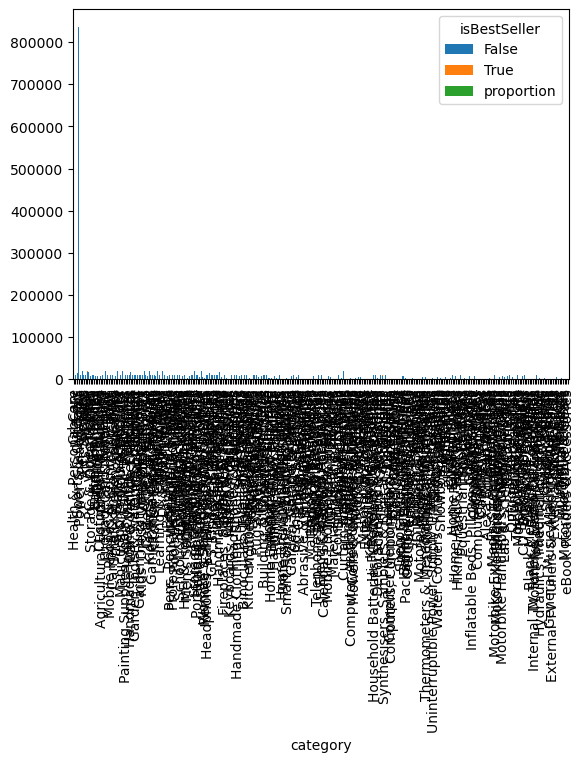

In [72]:
# 3. Visualizations: Visualize the relationship between product categories and the best-seller status using a stacked bar chart.
crosstab_category_bestseller.plot(kind="bar", stacked=True)
plt.show()

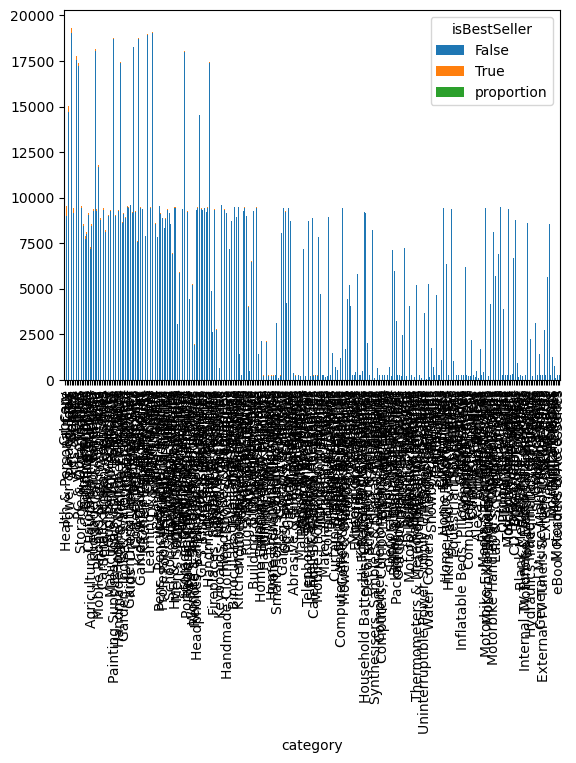

In [76]:
# Filter out rows where the 'True' column is 0:
crosstab_filtered = crosstab_category_bestseller[crosstab_category_bestseller[True] > 0]
# Filter out rows where the 'False' column is larger than 20000:
crosstab_filtered = crosstab_category_bestseller[crosstab_category_bestseller[False] < 20000]
# 3. Visualizations: Visualize the relationship between product categories and the best-seller status using a stacked bar chart.
crosstab_filtered.plot(kind="bar", stacked=True)
plt.show()

In [78]:
# Part 2: Exploring Product Prices and Ratings Across Categories and Brands
# Objective: Investigate how different product categories influence product prices.
# 0. Preliminary Step: Remove outliers in product prices.
# For this purpose, we can use the IQR (Interquartile Range) method. 
# Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR
# will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
# Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.

# Compute Q1 (25th percentile) and Q3 (75th percentile)
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)

# Compute the Interquartile Range (IQR)
IQR = Q3 - Q1

# Define lower and upper bounds for non-outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter the DataFrame to remove outliers
df_no_price_outliers = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]

# Display results
print("Original DataFrame:\n", df)
print("\nFiltered DataFrame (No Outliers):\n", df_no_price_outliers)

Original DataFrame:
              uid        asin  \
0              1  B09B96TG33   
1              2  B01HTH3C8S   
2              3  B09B8YWXDF   
3              4  B09B8T5VGV   
4              5  B09WX6QD65   
...          ...         ...   
2443646  2828589  B0CHSD7P2Q   
2443647  2828590  B0B7B8FNBQ   
2443648  2828591  B0BD5FL5FB   
2443649  2828592  B008OYLL4I   
2443650  2828593  B08P3W9B3T   

                                                     title  stars  reviews  \
0        Echo Dot (5th generation, 2022 release) | Big ...    4.7    15308   
1        Anker Soundcore mini, Super-Portable Bluetooth...    4.7    98099   
2        Echo Dot (5th generation, 2022 release) | Big ...    4.7    15308   
3        Echo Dot with clock (5th generation, 2022 rele...    4.7     7205   
4        Introducing Echo Pop | Full sound compact Wi-F...    4.6     1881   
...                                                    ...    ...      ...   
2443646  Motorbike Armour, Motorbike Clothing, C

C:\Users\admin\AppData\Local\Temp\ipykernel_31556\1187991651.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_20top_filtered, x='category', y='price', palette="coolwarm")


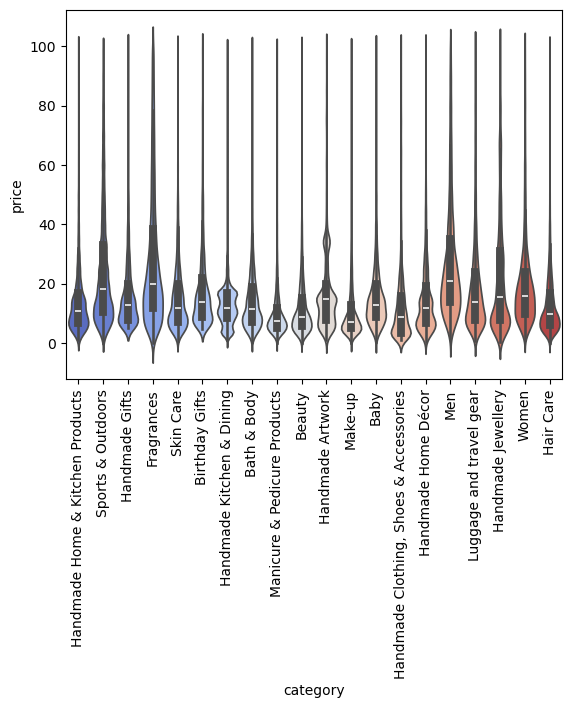

In [80]:
# 1. Violin Plots: Use a violin plot to visualize the distribution of `price` across different product `categories`. 
# Filter out the top 20 categories based on count for better visualization.

# Get the top 20 categories by count
top_20_categories = df_no_price_outliers['category'].value_counts().nlargest(20).index

# Filter the DataFrame to include only the top 20 categories
df_20top_filtered = df_no_price_outliers[df_no_price_outliers['category'].isin(top_20_categories)]

# Create the violin plot
sns.violinplot(data=df_20top_filtered, x='category', y='price', palette="coolwarm")
plt.xticks(rotation=90)  # Rotate category labels for better readability
plt.show()

In [82]:
# Which product category tends to have the highest median price? Don't filter here by top categories.

# Calculate the median price for each category
category_median_prices = df_no_price_outliers.groupby('category')['price'].median()

# Find the category with the highest median price
category_highest_median_price = category_median_prices.idxmax()

print("Category with highest median price:", category_highest_median_price)

Category with highest median price: Desktop PCs


In [88]:
# 2. Bar Charts: Create a bar chart comparing the average price of products for the top 10 product categories (based on count).

# Select the top 10 product categories (based on count)
top_10_category_by_count = df_no_price_outliers.groupby('category')['price'].count()
top_10_category_by_count

category
3D Printers                          36
3D Printing & Scanning             3253
Abrasive & Finishing Products       247
Action Cameras                     1072
Adapters                            254
                                  ...  
Wind Instruments                    118
Window Treatments                   237
Women                             17476
Women's Sports & Outdoor Shoes     1454
eBook Readers & Accessories         210
Name: price, Length: 296, dtype: int64

C:\Users\admin\AppData\Local\Temp\ipykernel_31556\492418015.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=avg_price_per_category.index, y=avg_price_per_category.values, palette="coolwarm")


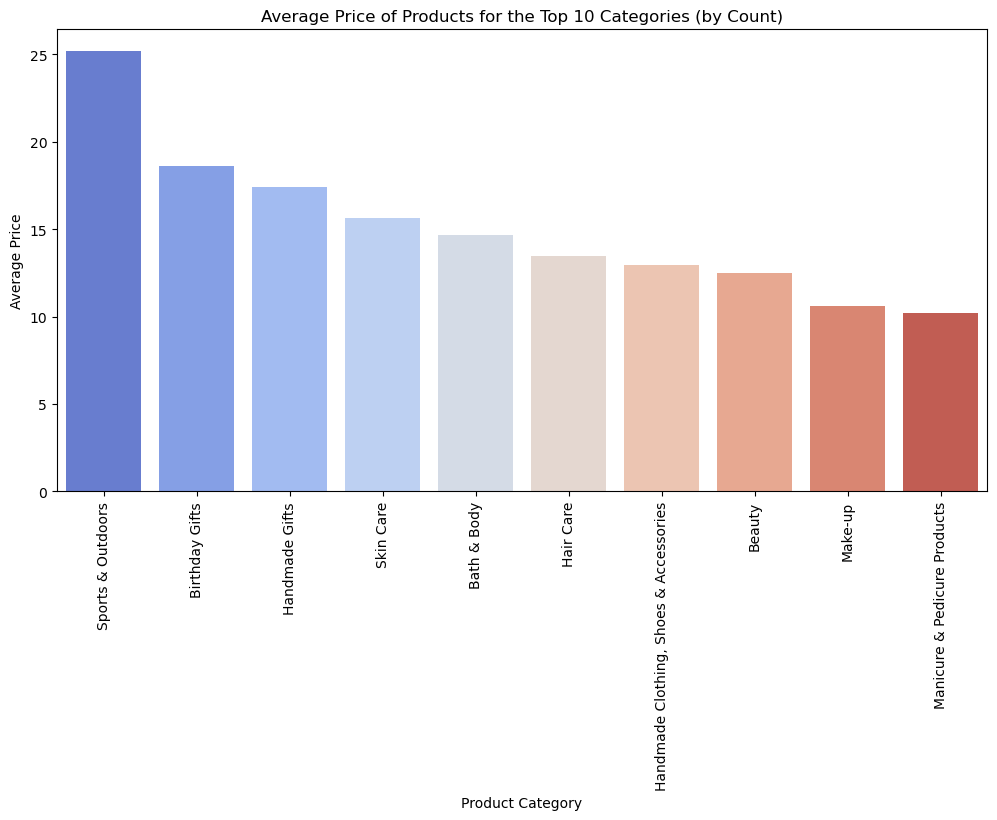

In [92]:
# 2. Bar Charts: Create a bar chart comparing the average price of products for the top 10 product categories (based on count).

# Find the top 10 product categories by count
top_10_category_by_count = df_no_price_outliers['category'].value_counts().nlargest(10).index

# Filter the DataFrame for only these top 10 categories
df_top_10 = df_no_price_outliers[df_no_price_outliers['category'].isin(top_10_category_by_count)]

# Calculate the average price for each of these top 10 categories
avg_price_per_category = df_top_10.groupby('category')['price'].mean().sort_values(ascending=False)

# Create the bar chart
plt.figure(figsize=(12,6))
sns.barplot(x=avg_price_per_category.index, y=avg_price_per_category.values, palette="coolwarm")

# Customize the plot
plt.xticks(rotation=90)  
plt.xlabel("Product Category")
plt.ylabel("Average Price")
plt.title("Average Price of Products for the Top 10 Categories (by Count)")
plt.show()

In [96]:
# Which product category commands the highest average price? Don't filter here by top categories.

# Calculate the average price per category
avg_price_per_category_all = df.groupby('category')['price'].mean().sort_values(ascending=False)
category_highest_avg_price = avg_price_per_category_all.idxmax()

print("Category with highest average price:", category_highest_avg_price)

Category with highest average price: Laptops


C:\Users\admin\AppData\Local\Temp\ipykernel_31556\3574151726.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top_10, x='category', y='stars', palette="coolwarm")


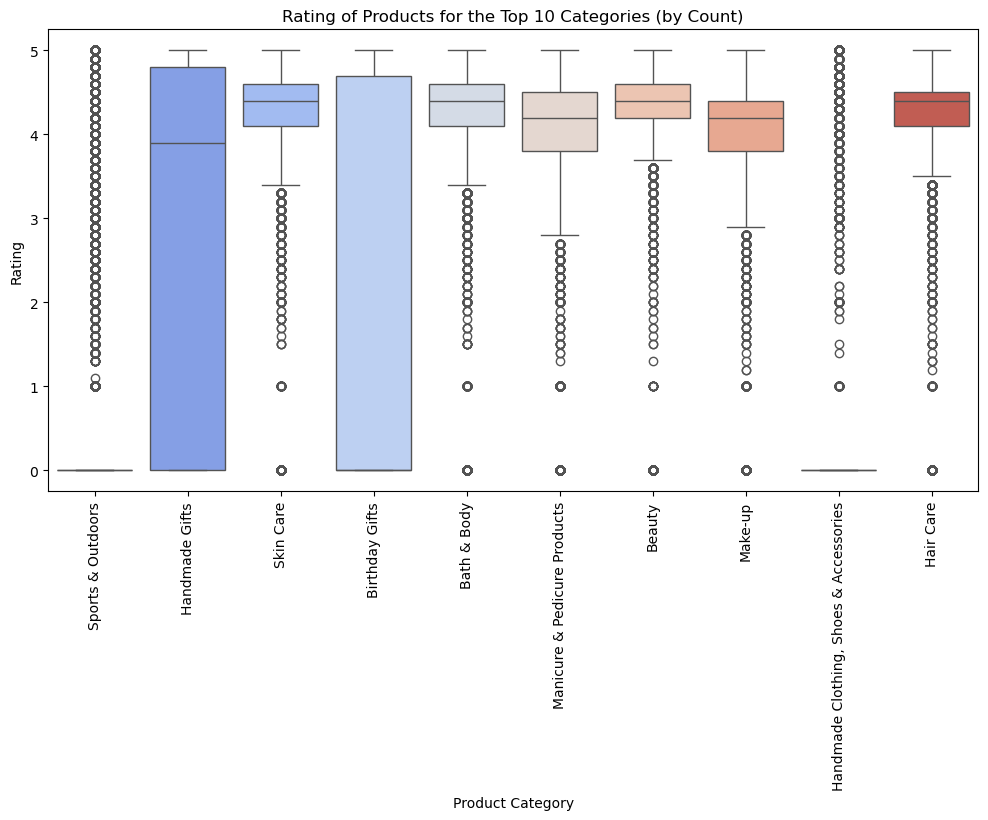

In [102]:
# 3. Box Plots: Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. 
# Filter out the top 10 categories based on count for better visualization.

# Find the top 10 product categories by count
top_10_category_by_count = df_no_price_outliers['category'].value_counts().nlargest(10).index

# Filter the DataFrame for only these top 10 categories
df_top_10 = df_no_price_outliers[df_no_price_outliers['category'].isin(top_10_category_by_count)]

# Create the bar chart
plt.figure(figsize=(12,6))
sns.boxplot(data=df_top_10, x='category', y='stars', palette="coolwarm")

# Customize the plot
plt.xticks(rotation=90)  
plt.xlabel("Product Category")
plt.ylabel("Rating")
plt.title("Rating of Products for the Top 10 Categories (by Count)")
plt.show()

In [142]:
# Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

# Calculate the median rating per category
median_rating_per_category_all = df_no_price_outliers.groupby('category')['stars'].median().sort_values(ascending=False)
highest_median_rating_per_category = median_rating_per_category_all.idxmax()

print("Category with highest median rating:", highest_median_rating_per_category)

Category with highest median rating: Computer Memory


In [148]:
# Part 3: Investigating the Interplay Between Product Prices and Ratings
# Objective: Analyze how product ratings (`stars`) correlate with product prices.
# 1. Correlation Coefficients: Calculate the correlation coefficient between `price` and `stars`.

# Calculating the Pearson correlation coefficient between 'price' and 'stars' columns
correlation_Pearson = df_no_price_outliers['price'].corr(df_no_price_outliers['stars'])
correlation_Pearson

-0.0776729987818137

In [150]:
# Calculating the Spearman rank correlation coefficient between 'price' and 'stars' columns
correlation_Spearman = df_no_price_outliers['price'].corr(df_no_price_outliers['stars'], method='spearman')
correlation_Spearman

-0.06679697280768314

In [112]:
# Is there a significant correlation between product price and its rating?
# No there is no correlation between price and rating of products.

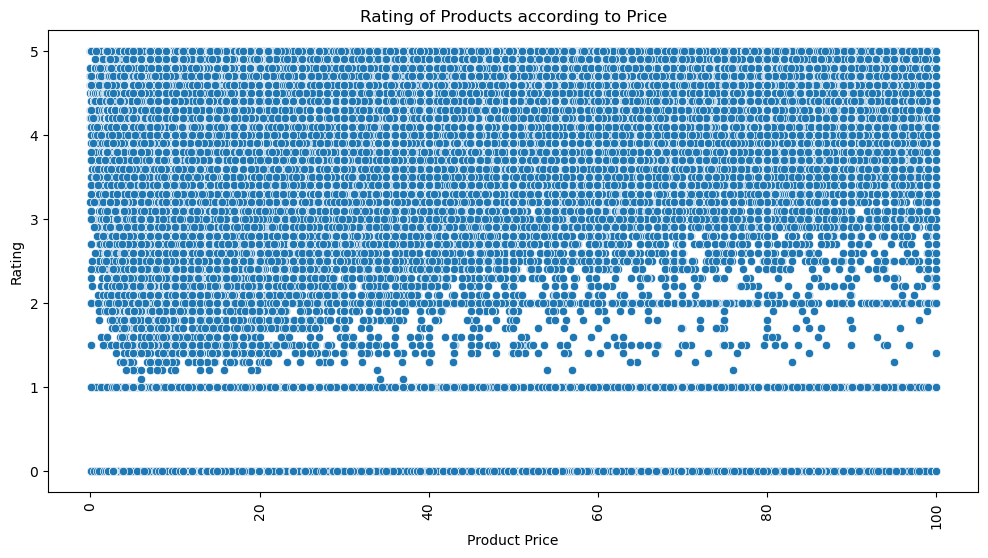

In [152]:
# 2. Visualizations: Use a scatter plot to visualize the relationship between product rating and price. 

plt.figure(figsize=(12,6))
sns.scatterplot(data=df_no_price_outliers, x='price', y='stars')

# Customize the plot
plt.xticks(rotation=90)  
plt.xlabel("Product Price")
plt.ylabel("Rating")
plt.title("Rating of Products according to Price")
plt.show()

In [118]:
# What patterns can you observe?
# Price and Rating of Products are independent of each other.
# Many Products have no rating (0 stars).
# Rated Products show a positive skew towards higher ratings.

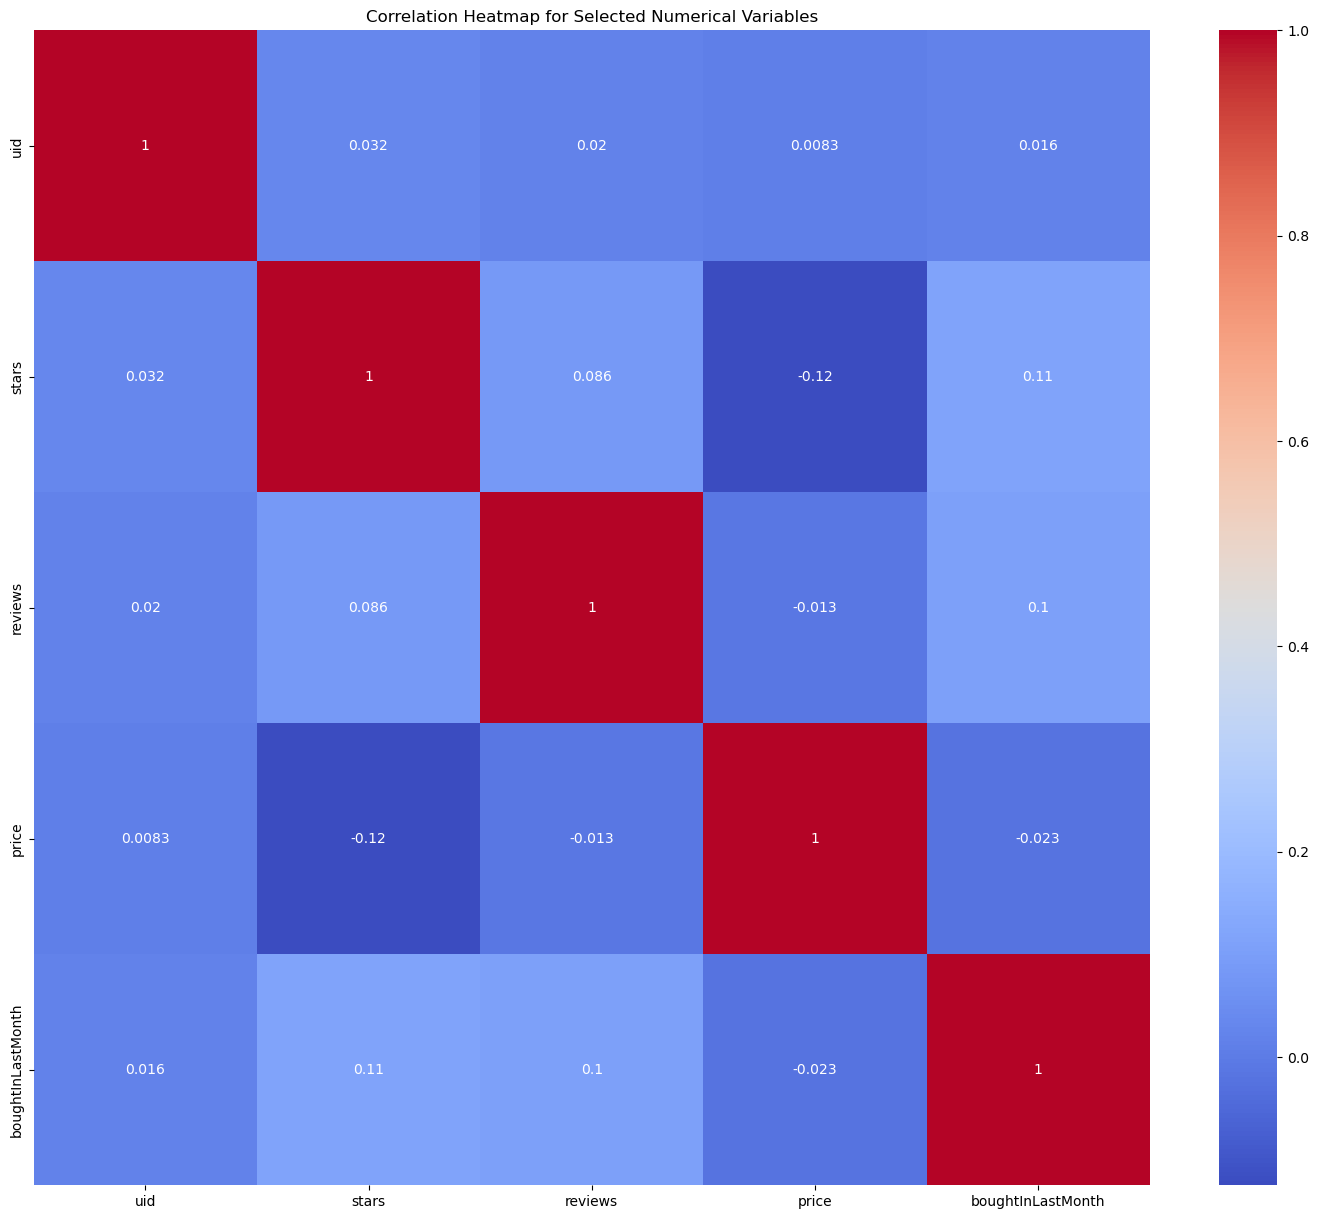

In [158]:
# Use a correlation heatmap to visualize correlations between all numerical variables.

# Separating between discrete and continuous variables, as discrete ones could potentially be treated as categorical.
# Remember to adjust the threshold (in this case, < 20) based on your dataset's specific characteristics and domain knowledge.
potential_categorical_from_numerical = df_no_price_outliers.select_dtypes("number").loc[:, df_no_price_outliers.select_dtypes("number").nunique() < 5]
potential_categorical_from_numerical

# Extracting columns with object (typically string) data types to create a categorical dataframe
# For demonstration purposes, let's consider the columns in potential_categorical_from_numerical as categorical variables.
df_categorical = pd.concat([df.select_dtypes("object"), potential_categorical_from_numerical], axis=1)

# Adjusting the numerical dataframe by removing the moved columns
df_numerical = df.select_dtypes("number").drop(columns=potential_categorical_from_numerical.columns)

correlation_matrix = df_numerical.corr()

# Setting up the matplotlib figure with an appropriate size
plt.figure(figsize=(18, 15))

# Drawing the heatmap for the numerical columns
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap for Selected Numerical Variables")
plt.show()

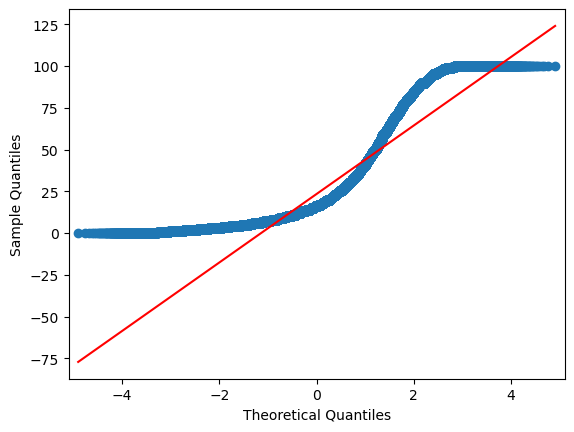

In [154]:
# Examine if product prices typically follow a normal distribution using a QQ plot. 
# Y-Axis = price, X-Axis = StdDev

import statsmodels.api as sm

sm.qqplot(df_no_price_outliers['price'], line='s');
plt.show()

In [160]:
# Product prices do not follow a normal distribution.

In [ ]:
# Bonus: Do the same analysis without taking out the outliers. What are your insights?

In [ ]:
# Business-centric report summarizing the findings?